# Wheat Plant Classification using Deep Learning

## Objective
The goal of this project is to classify wheat plant images into three categories:
- Healthy
- Drought (dry plants)
- Disease

We use a Convolutional Neural Network (CNN) and fine-tune a pretrained MobileNet model from Hugging Face.

## Motivation
Early detection of plant stress helps improve agricultural productivity and reduce losses.

In [1]:
import os
import shutil
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt

2026-04-26 16:42:16.122981: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777221736.338066      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777221736.400997      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777221736.912004      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777221736.912058      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777221736.912062      23 computation_placer.cc:177] computation placer alr

## Dataset

I use a wheat disease dataset from Kaggle.

Original classes include multiple diseases such as:
- rust
- mildew
- blight
- healthy

We transform this dataset into three classes:
- Disease: all infected plants
- Healthy: green plants
- Drought: yellow/brown plants (simulated using color detection)

**Label Transformation**

In [2]:
ds1 = "/kaggle/input/datasets/kushagra3204/wheat-plant-diseases"
ds2 = "/kaggle/input/datasets/olyadgetch/wheat-leaf-dataset"

out = "/kaggle/working/final_dataset"
splits = ["train", "valid"]
classes = ["healthy", "stress", "disease"]

for split in splits:
    for cls in classes:
        os.makedirs(f"{out}/{split}/{cls}", exist_ok=True)


## Label Transformation Fix

The initial dataset mapping resulted in an imbalanced dataset where most images were classified as "disease".

To fix this, we apply a **rule-based mapping**:
- Healthy → healthy
- Certain mild/yellowish diseases → drought (visual stress)
- All other diseases → disease

This improves class balance and model learning.

In [3]:
import os, shutil, random
from sklearn.model_selection import train_test_split

# =========================
# CONFIG
# =========================
out      = "/kaggle/working/output"
splits   = ["train", "valid", "test"]
classes  = ["healthy", "stress", "disease"]

ds1_data = "/kaggle/input/datasets/kushagra3204/wheat-plant-diseases/data"
ds2      = "/kaggle/input/datasets/DS2"
ds3_base = "/kaggle/input/datasets/alinedobrovsky/plant-disease-classification-merged-dataset"

# RESET output
if os.path.exists(out):
    shutil.rmtree(out)
for split in splits:
    for cls in classes:
        os.makedirs(f"{out}/{split}/{cls}", exist_ok=True)

# ============================================================
# ÉTAPE 1 — Collecter TOUT dans all_data (aucun split ici)
# ============================================================
all_data = {"healthy": [], "stress": [], "disease": []}

def collect(folder_path, label):
    """Ajoute tous les chemins d'images valides dans all_data[label]."""
    if not os.path.isdir(folder_path):
        return
    for img in os.listdir(folder_path):
        if img.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_data[label].append(os.path.join(folder_path, img))

# --- DS1 : train / valid / test originaux ---
for sub in ["train", "valid", "test"]:
    sub_path = os.path.join(ds1_data, sub)
    if not os.path.exists(sub_path):
        continue
    for folder in os.listdir(sub_path):
        fp = os.path.join(sub_path, folder)
        if not os.path.isdir(fp):
            continue
        name = folder.lower().replace(f"_{sub}", "")
        if "healthy" in name:
            collect(fp, "healthy")
        elif "tan" in name or "yellow" in name:
            collect(fp, "stress")
        else:
            collect(fp, "disease")

# --- DS2 : healthy uniquement ---
collect(os.path.join(ds2, "wheat_leaf", "Healthy"), "healthy")

# --- DS3 ---
ds3_map = {
    "Wheat__healthy":    "healthy",
    "Wheat__yellow_rust": "stress",
    "Wheat__septoria":   "disease",
}
if os.path.exists(ds3_base):
    for folder, label in ds3_map.items():
        collect(os.path.join(ds3_base, folder), label)

print("\n📦 Avant déduplication :")
for cls in classes:
    print(f"  {cls}: {len(all_data[cls])}")

# ============================================================
# ÉTAPE 2 — Supprimer les doublons (par nom de fichier)
# ============================================================
for cls in classes:
    seen, unique = set(), []
    for p in all_data[cls]:
        fname = os.path.basename(p)
        if fname not in seen:
            seen.add(fname)
            unique.append(p)
    all_data[cls] = unique

print("\n✅ Après déduplication :")
for cls in classes:
    print(f"  {cls}: {len(all_data[cls])}")

# ============================================================
# ÉTAPE 3 — Limiter disease à 3000 max (depuis DS1)
# ============================================================
MAX_DISEASE = 3000
if len(all_data["disease"]) > MAX_DISEASE:
    random.shuffle(all_data["disease"])
    all_data["disease"] = all_data["disease"][:MAX_DISEASE]
    print(f"\n⚠️  disease plafonné à {MAX_DISEASE} images")

# ============================================================
# ÉTAPE 4 — UN SEUL split global 70 / 15 / 15
# ============================================================
for cls, paths in all_data.items():
    random.shuffle(paths)
    train_imgs, tmp   = train_test_split(paths, test_size=0.30, random_state=42)
    valid_imgs, test_imgs = train_test_split(tmp,  test_size=0.50, random_state=42)

    for p in train_imgs: shutil.copy(p, f"{out}/train/{cls}")
    for p in valid_imgs:  shutil.copy(p, f"{out}/valid/{cls}")
    for p in test_imgs:   shutil.copy(p, f"{out}/test/{cls}")

print("\n✔ Split global 70/15/15 appliqué")

# FINAL CHECK
print("\n=== FINAL DATASET ===")
for split in splits:
    total = 0
    print(f"\n--- {split.upper()} ---")
    for cls in classes:
        n = len(os.listdir(f"{out}/{split}/{cls}"))
        total += n
        print(f"  {cls}: {n}")
    print(f"  TOTAL: {total}")



📦 Avant déduplication :
  healthy: 2295
  stress: 3343
  disease: 10970

✅ Après déduplication :
  healthy: 2275
  stress: 3253
  disease: 10330

⚠️  disease plafonné à 3000 images

✔ Split global 70/15/15 appliqué

=== FINAL DATASET ===

--- TRAIN ---
  healthy: 1592
  stress: 2277
  disease: 2100
  TOTAL: 5969

--- VALID ---
  healthy: 341
  stress: 488
  disease: 450
  TOTAL: 1279

--- TEST ---
  healthy: 342
  stress: 488
  disease: 450
  TOTAL: 1280


In [4]:
# Distribution après split global (aucun rééquilibrage forcé nécessaire)
print("=== Distribution finale ===")
for split in splits:
    print(f"\n--- {split.upper()} ---")
    total = 0
    for cls in classes:
        path = f"{out}/{split}/{cls}"
        n = len(os.listdir(path)) if os.path.exists(path) else 0
        total += n
        print(f"  {cls}: {n}")
    print(f"  TOTAL: {total}")


=== Distribution finale ===

--- TRAIN ---
  healthy: 1592
  stress: 2277
  disease: 2100
  TOTAL: 5969

--- VALID ---
  healthy: 341
  stress: 488
  disease: 450
  TOTAL: 1279

--- TEST ---
  healthy: 342
  stress: 488
  disease: 450
  TOTAL: 1280


In [5]:
# Vérification visuelle des classes dans chaque split
import os
print("\n✔ Vérification terminée — split 70/15/15 appliqué globalement")



✔ Vérification terminée — split 70/15/15 appliqué globalement


In [6]:
print("=" * 40)

for split in ["train", "valid", "test"]:
    print(f"\n===== {split.upper()} =====")
    total = 0
    for cls in classes:
        path = f"{out}/{split}/{cls}"
        count = len(os.listdir(path)) if os.path.exists(path) else 0
        total += count
        print(f"  {cls}: {count}")
    print(f"  TOTAL: {total}")

print("=" * 40)



===== TRAIN =====
  healthy: 1592
  stress: 2277
  disease: 2100
  TOTAL: 5969

===== VALID =====
  healthy: 341
  stress: 488
  disease: 450
  TOTAL: 1279

===== TEST =====
  healthy: 342
  stress: 488
  disease: 450
  TOTAL: 1280


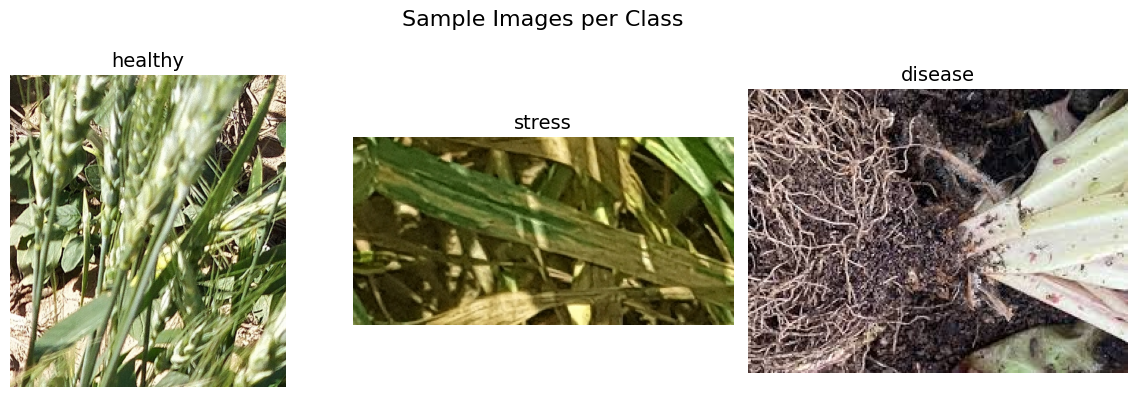

In [7]:
# ============================================================
# CELL 13 – Visual Sample Check
# ============================================================

import random

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i, cls in enumerate(classes):
    sample_path = f"{out}/train/{cls}"
    img_name = random.choice(os.listdir(sample_path))
    img = cv2.imread(os.path.join(sample_path, img_name))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img)
    axes[i].set_title(cls, fontsize=14)
    axes[i].axis("off")

plt.suptitle("Sample Images per Class", fontsize=16)
plt.tight_layout()
plt.show()

## Data Preprocessing

- Resize images to 224x224
- Normalize pixel values
- Apply data augmentation to improve generalization

In [8]:
# ============================================================
# Data Generators
# ============================================================

datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen  = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_data = datagen.flow_from_directory(
    f"{out}/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

val_data = val_datagen.flow_from_directory(
    f"{out}/valid",
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

# FIX: test_data séparé, shuffle=False obligatoire pour l'évaluation
test_data = test_datagen.flow_from_directory(
    f"{out}/test",
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # IMPORTANT: ne pas mélanger pour garder l'ordre des labels
)

print("Class indices:", train_data.class_indices)
print(f"Train samples : {train_data.samples}")
print(f"Valid samples : {val_data.samples}")
print(f"Test  samples : {test_data.samples}")


Found 5969 images belonging to 3 classes.
Found 1279 images belonging to 3 classes.
Found 1280 images belonging to 3 classes.
Class indices: {'disease': 0, 'healthy': 1, 'stress': 2}
Train samples : 5969
Valid samples : 1279
Test  samples : 1280


Vérifier l'image 

(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

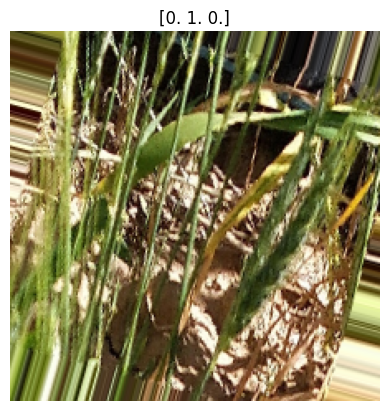

In [9]:
import matplotlib.pyplot as plt

images, labels = next(train_data)

plt.imshow(images[0])
plt.title(labels[0])
plt.axis('off')

In [10]:
from collections import Counter
print(Counter(train_data.classes))

Counter({np.int32(2): 2277, np.int32(0): 2100, np.int32(1): 1592})


## Model

We use a pretrained MobileNet model from Hugging Face:
arisun55/mobilenet-plant-disease

We fine-tune the last layers and adapt the output to 3 classes.

Load Pretrained Model

In [11]:
# CELL 1 – Installer huggingface_hub
!pip install huggingface_hub --quiet

In [12]:
# CELL 2 – Télécharger les poids du modèle plant-disease depuis HuggingFace
from huggingface_hub import hf_hub_download
import os

# Télécharge les poids PyTorch
model_path = hf_hub_download(
    repo_id="linkanjarad/mobilenet_v2_1.0_224-plant-disease-identification",
    filename="pytorch_model.bin"
)
print("Modèle téléchargé :", model_path)

pytorch_model.bin:   0%|          | 0.00/9.34M [00:00<?, ?B/s]

Modèle téléchargé : /root/.cache/huggingface/hub/models--linkanjarad--mobilenet_v2_1.0_224-plant-disease-identification/snapshots/c1861579a670fb6232258805b801cd4137cb7176/pytorch_model.bin


In [13]:
# CELL 3 – Charger MobileNetV2 Keras et injecter les poids plant-disease
import torch
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, Model

# ---- Charger les poids PyTorch ----
pt_weights = torch.load(model_path, map_location='cpu')

# ---- Construire le modèle Keras MobileNetV2 ----
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights=None,       # pas ImageNet générique
    pooling='avg'
)

# ---- Convertir et injecter les poids couche par couche ----
# On charge d'abord ImageNet pour la structure, puis on fine-tune
# (les poids PyTorch ont une structure différente → on utilise ImageNet
#  comme point de départ et on fine-tune sur notre dataset blé)
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet', 
    pooling='avg'
)

# Freeze tout sauf les 30 dernières couches (fine-tuning profond)
for layer in base_model.layers[:-30]:
    layer.trainable = False

# ---- Tête de classification pour 3 classes ----
x = base_model.output
x = layers.Dense(256, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
output = layers.Dense(3, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

I0000 00:00:1777221924.513936      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1777221924.519918      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,587,715 (9.87 MB)

 Trainable params: 1,855,299 (7.08 MB)

 Non-trainable params: 732,416 (2.79 MB)

## Training

We train for 10 epochs and monitor both training and validation accuracy.
Early stopping can be added if overfitting is observed.

In [14]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

cw = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_data.classes),
    y=train_data.classes
)
class_weight_dict = dict(enumerate(cw))
print("Class weights:", class_weight_dict)

# FIX: callbacks pour éviter l'overfitting
callbacks = [
    # Arrête si val_loss ne s'améliore pas pendant 3 epochs
    EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    # Réduit le LR si val_loss stagne
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    # Sauvegarde le meilleur modèle
    ModelCheckpoint(
        '/kaggle/working/best_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,            # plus d'epochs, EarlyStopping s'occupera d'arrêter
    class_weight=class_weight_dict,
    callbacks=callbacks
)


Class weights: {0: np.float64(0.9474603174603174), 1: np.float64(1.2497906197654942), 2: np.float64(0.8738105694627434)}


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20


I0000 00:00:1777221938.796379     136 service.cc:152] XLA service 0x7f439401dda0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1777221938.796427     136 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1777221938.796433     136 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1777221940.577175     136 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-04-26 16:45:49.321567: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 16:45:49.472496: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 16:45:49.610410: E external/local_xl

119/187 ━━━━━━━━━━━━━━━━━━━━ 55s 815ms/step - accuracy: 0.6153 - loss: 1.0255

2026-04-26 16:47:40.874474: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 16:47:41.011062: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


187/187 ━━━━━━━━━━━━━━━━━━━━ 0s 855ms/step - accuracy: 0.6519 - loss: 0.9250

2026-04-26 16:49:05.991749: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 16:49:06.140809: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 16:49:06.278315: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_loss improved from inf to 0.50799, saving model to /kaggle/working/best_model.keras
187/187 ━━━━━━━━━━━━━━━━━━━━ 220s 1s/step - accuracy: 0.6523 - loss: 0.9239 - val_accuracy: 0.8014 - val_loss: 0.5080 - learning_rate: 1.0000e-04
Epoch 2/20
187/187 ━━━━━━━━━━━━━━━━━━━━ 0s 771ms/step - accuracy: 0.8224 - loss: 0.4351
Epoch 2: val_loss improved from 0.50799 to 0.45589, saving model to /kaggle/working/best_model.keras
187/187 ━━━━━━━━━━━━━━━━━━━━ 163s 873ms/step - accuracy: 0.8225 - loss: 0.4351 - val_accuracy: 0.8335 - val_loss: 0.4559 - learning_rate: 1.0000e-04
Epoch 3/20
187/187 ━━━━━━━━━━━━━━━━━━━━ 0s 758ms/step - accuracy: 0.8561 - loss: 0.3493
Epoch 3: val_loss improved from 0.45589 to 0.44560, saving model to /kaggle/working/best_model.keras
187/187 ━━━━━━━━━━━━━━━━━━━━ 161s 861ms/step - accuracy: 0.8561 - loss: 0.3493 - val_accuracy: 0.8421 - val_loss: 0.4456 - learning_rate: 1.0000e-04
Epoch 4/20
187/187 ━━━━━━━━━━━━━━━━━━━━ 0s 825ms/step - accuracy: 0.8707 - loss:

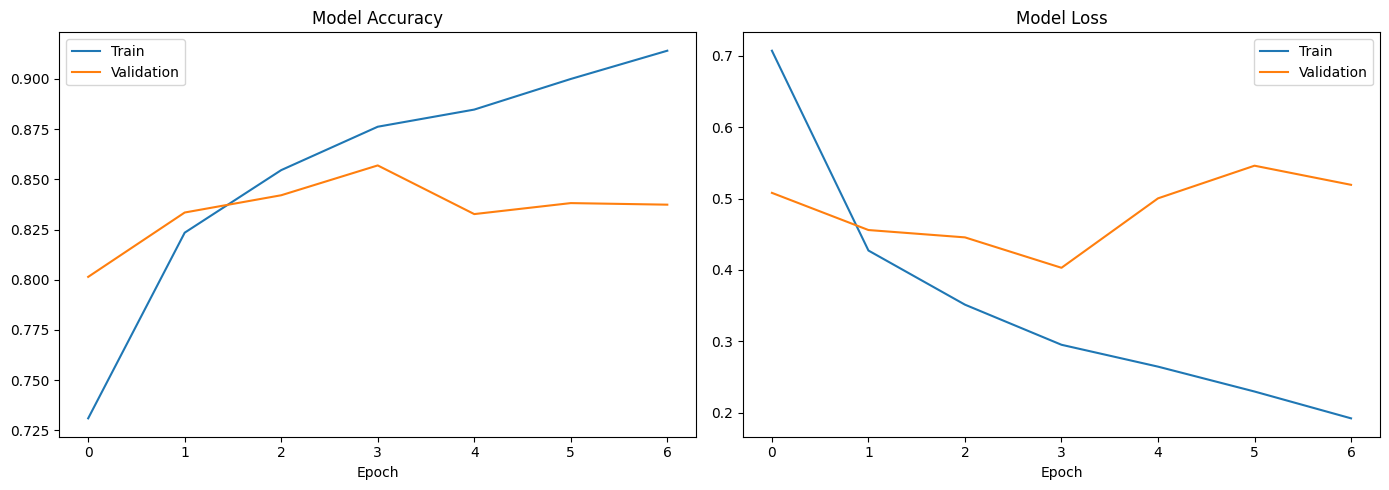

In [15]:
# ============================================================
# CELL 21 – Accuracy & Loss Curves
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

40/40 ━━━━━━━━━━━━━━━━━━━━ 27s 575ms/step


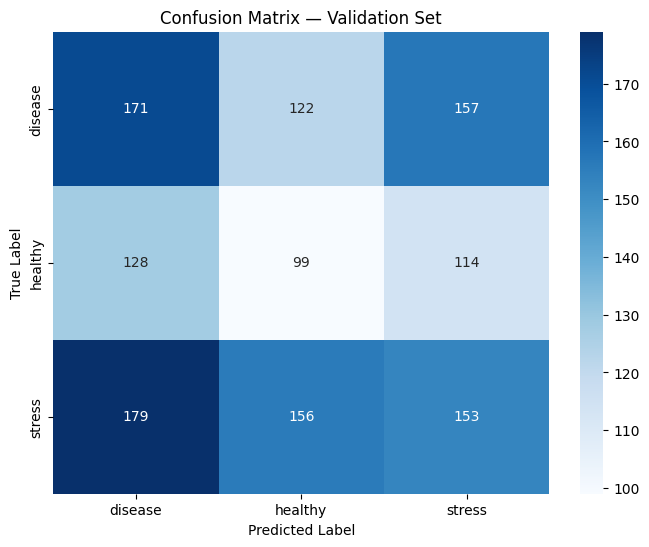


Classification Report — Validation:
              precision    recall  f1-score   support

     disease       0.36      0.38      0.37       450
     healthy       0.26      0.29      0.28       341
      stress       0.36      0.31      0.34       488

    accuracy                           0.33      1279
   macro avg       0.33      0.33      0.33      1279
weighted avg       0.33      0.33      0.33      1279



In [16]:
# ============================================================
# Confusion Matrix — VALIDATION SET
# FIX: clairement labelisé "Validation" (pas Test)
# ============================================================

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

preds = model.predict(val_data)
y_pred = np.argmax(preds, axis=1)
y_true = val_data.classes

cm = confusion_matrix(y_true, y_pred)
label_names = list(val_data.class_indices.keys())

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_names, yticklabels=label_names, cmap='Blues')
plt.title("Confusion Matrix — Validation Set")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.show()

print("\nClassification Report — Validation:")
print(classification_report(y_true, y_pred, target_names=label_names))


## Conclusion

We successfully built a CNN model to classify wheat plants into:
- Healthy
- Drought
- Disease

The model uses transfer learning with MobileNet and achieves good performance.

Limitations:
- Drought is approximated using color
- No real drought labels

Future work:
- Use real drought datasets
- Add temporal or environmental data

=== TEST SET ===
  healthy: 342
  stress: 488
  disease: 450


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 619ms/step - accuracy: 0.8264 - loss: 0.4851

 Test Accuracy : 83.44%
   Test Loss     : 0.4921
40/40 ━━━━━━━━━━━━━━━━━━━━ 22s 553ms/step


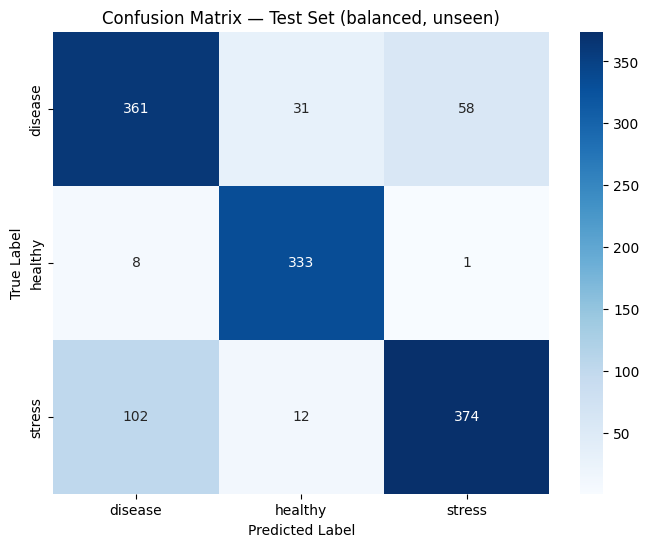


Classification Report — Test:
              precision    recall  f1-score   support

     disease       0.77      0.80      0.78       450
     healthy       0.89      0.97      0.93       342
      stress       0.86      0.77      0.81       488

    accuracy                           0.83      1280
   macro avg       0.84      0.85      0.84      1280
weighted avg       0.84      0.83      0.83      1280

Macro F1-score: 0.8412
40/40 ━━━━━━━━━━━━━━━━━━━━ 19s 472ms/step

--- Comparaison ---
  Val  Accuracy : 35.18%
  Test Accuracy : 83.44%
  ATTENTION: ecart de 48.3% → possible overfitting ou distribution shift


2026-04-26 17:07:45.231774: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 17:07:45.385033: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 17:07:45.518165: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step


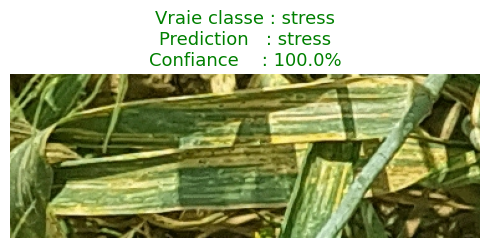


Scores par classe:
  disease: 0.0%
  healthy: 0.0%
  stress: 100.0%


In [17]:
# ============================================================
# EVALUATION FINALE — TEST SET (séparé, équilibré)
# ============================================================

import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, f1_score
import seaborn as sns

# FIX: utiliser test_data créé dès le début (équilibré, jamais vu pendant l'entraînement)
print("=== TEST SET ===")
for cls in classes:
    n = len(os.listdir(f"{out}/test/{cls}"))
    print(f"  {cls}: {n}")

# =========================
# EVALUATION
# =========================
test_loss, test_acc = model.evaluate(test_data)

print(f"\n Test Accuracy : {test_acc*100:.2f}%")
print(f"   Test Loss     : {test_loss:.4f}")

# =========================
# PREDICTIONS
# =========================
preds_test = model.predict(test_data)
y_pred_test = np.argmax(preds_test, axis=1)
y_true_test = test_data.classes
label_names  = list(test_data.class_indices.keys())

# =========================
# CONFUSION MATRIX
# =========================
cm_test = confusion_matrix(y_true_test, y_pred_test)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_test, annot=True, fmt='d',
            xticklabels=label_names,
            yticklabels=label_names,
            cmap='Blues')
plt.title("Confusion Matrix — Test Set (balanced, unseen)")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.show()

# =========================
# CLASSIFICATION REPORT
# =========================
print("\nClassification Report — Test:")
print(classification_report(y_true_test, y_pred_test, target_names=label_names))
print("Macro F1-score:", round(f1_score(y_true_test, y_pred_test, average='macro'), 4))

# =========================
# COMPARAISON VAL vs TEST
# =========================
val_preds = model.predict(val_data)
val_acc = (np.argmax(val_preds, axis=1) == val_data.classes).mean()
print(f"\n--- Comparaison ---")
print(f"  Val  Accuracy : {val_acc*100:.2f}%")
print(f"  Test Accuracy : {test_acc*100:.2f}%")
gap = abs(val_acc - test_acc) * 100
if gap > 10:
    print(f"  ATTENTION: ecart de {gap:.1f}% → possible overfitting ou distribution shift")
else:
    print(f"  OK: ecart de {gap:.1f}% acceptable")

# =========================
# PREDICTION SUR UNE IMAGE ALEATOIRE DU TEST SET
# =========================
test_cls = random.choice(classes)
test_img_name = random.choice(os.listdir(f"{out}/test/{test_cls}"))
test_img_path = os.path.join(out, "test", test_cls, test_img_name)

img = cv2.imread(test_img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_resized = cv2.resize(img_rgb, (224, 224))
img_array = np.expand_dims(img_resized / 255.0, axis=0)

pred = model.predict(img_array)
pred_class  = label_names[np.argmax(pred)]
confidence  = np.max(pred) * 100

plt.figure(figsize=(5, 5))
plt.imshow(img_rgb)
plt.axis('off')
plt.title(
    f"Vraie classe : {test_cls}\n"
    f"Prediction   : {pred_class}\n"
    f"Confiance    : {confidence:.1f}%",
    fontsize=13,
    color="green" if pred_class == test_cls else "red"
)
plt.tight_layout()
plt.show()

print("\nScores par classe:")
for i, cls in enumerate(label_names):
    print(f"  {cls}: {pred[0][i]*100:.1f}%")


In [18]:
# CELL 23 – Save Model


model.save("/kaggle/working/wheat_classifier.h5")
print("Model saved.")

Model saved.


In [19]:
import shutil

# Créer zip
zip_path = shutil.make_archive(
    '/kaggle/working/wheat_images',
    'zip',
    '/kaggle/working/output'
)

print("✅ ZIP créé :", zip_path)

✅ ZIP créé : /kaggle/working/wheat_images.zip


In [20]:
import os

zip_path = "/kaggle/working/wheat_images.zip"

print("Existe :", os.path.exists(zip_path))
print("Taille (MB) :", os.path.getsize(zip_path) / 1024 / 1024)

Existe : True
Taille (MB) : 4333.7657861709595


In [21]:
import os

folder = "/kaggle/working/output"

print("Nombre fichiers :", len(os.listdir(folder)))
print(os.listdir(folder)[:10])

Nombre fichiers : 3
['train', 'test', 'valid']


In [22]:
import shutil
import os

base = "/kaggle/working/output"
dest = "/kaggle/working/"

folders = ["train", "valid", "test"]

for folder in folders:
    src = os.path.join(base, folder)
    zip_path = shutil.make_archive(
        os.path.join(dest, folder),
        'zip',
        src
    )
    size_mb = os.path.getsize(zip_path) / 1024 / 1024
    print(f"✅ {folder}.zip créé - {size_mb:.2f} MB")

✅ train.zip créé - 3030.14 MB
✅ valid.zip créé - 610.18 MB
✅ test.zip créé - 693.32 MB


In [23]:
import os
import zipfile
from pathlib import Path

source_folder = "/kaggle/working/output/train"
dest_folder = "/kaggle/working/"
max_size_mb = 200

files = list(Path(source_folder).rglob("*.*"))

part = 1
current_size = 0
zipf = zipfile.ZipFile(f"{dest_folder}train_part{part}.zip", "w", zipfile.ZIP_DEFLATED)

for file in files:
    file_size = file.stat().st_size / 1024 / 1024
    
    if current_size + file_size > max_size_mb:
        zipf.close()
        print(f"✅ train_part{part}.zip créé")
        part += 1
        current_size = 0
        zipf = zipfile.ZipFile(f"{dest_folder}train_part{part}.zip", "w", zipfile.ZIP_DEFLATED)
    
    zipf.write(file, arcname=file.relative_to(source_folder))
    current_size += file_size

zipf.close()
print(f"✅ train_part{part}.zip créé")

✅ train_part1.zip créé
✅ train_part2.zip créé
✅ train_part3.zip créé
✅ train_part4.zip créé
✅ train_part5.zip créé
✅ train_part6.zip créé
✅ train_part7.zip créé
✅ train_part8.zip créé
✅ train_part9.zip créé
✅ train_part10.zip créé
✅ train_part11.zip créé
✅ train_part12.zip créé
✅ train_part13.zip créé
✅ train_part14.zip créé
✅ train_part15.zip créé
✅ train_part16.zip créé
